# Identifying policy value under overlap

This native Julia companion preserves the public baskets, past-only context, 2018 standardization, action uniforms, fixed candidate policies, chronological folds and held-out split. Julia constructs all logged observations, fits reward models and computes every score. Zero/one action labels and zero-based policy numbers remain in the displayed results; native API calls use Julia indices. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## Building an action log from public basket returns

The public archive supplies the two returns that could be received on every date. The defensive basket is the equal weighted return of Food, Smoke, Health, and Utilities. The cyclical basket is the equal weighted return of Building Materials, Steel, Machinery, and Automobiles. The action log is generated because the archive contains returns but no historical record of a decision maker choosing between these baskets.

Let $Y_i(0)$ and $Y_i(1)$ be the two public basket returns on date $i$. The realized reward is

$$
Y_i=Y_i(A_i),
$$

where $A_i=0$ selects the defensive basket and $A_i=1$ selects the cyclical basket. The context $X_i$ contains a twenty day mean return spread, a twenty day volatility measure, and the previous day's spread. Every context value is formed before date $i$'s reward.

Row,Item,Value
,String,Any
1,Public source,Kenneth R. French 49 Industry Portfolios
2,Stored archive,49_Industry_Portfolios_daily_CSV.zip
3,Archive bytes,4173817
4,Analysis start,2019-01-02
5,Analysis end,2023-12-29
6,Complete dates,1258
7,Download during execution,None


Row,Action,Basket,Industries,Daily return rule
,Int64,String,String,String
1,0,Defensive,"Food, Smoke, Health, Utilities",Equal weighted
2,1,Cyclical,"Building Materials, Steel, Machinery, Automobiles",Equal weighted


Row,Component,Source or rule
,String,Any
1,Potential rewards,Both public basket returns on the same date
2,Context,Past returns only
3,Behavior action,"Generated from a declared probability and random state 9,101"
4,Behavior probability floor,0.1
5,Target policies,Five fixed rules declared before held-out evaluation


Row,Context,Dates,Mean,Standard deviation,Minimum,Maximum
,String,Int64,Float64,Float64,Float64,Float64
1,Past mean spread,1258,0.000769984,0.00304686,-0.0124375,0.0108112
2,Past volatility,1258,0.0123416,0.00794732,0.00346865,0.0647066
3,Past one-day spread,1258,0.000776232,0.0135108,-0.0483,0.058375


Row,Quantity,Value
,String,Real
1,Minimum action probability,0.100043
2,Maximum action probability,0.899957
3,Mean probability of action 1,0.506933
4,Realized share of action 1,0.509539
5,Action 0 dates,617
6,Action 1 dates,641


Row,Policy,Probability of action 1
,String,String
1,Always defensive,0
2,Always cyclical,1
3,Positive spread threshold,One when the past mean spread is positive
4,Smooth momentum,Logistic function of 1.5 times the past mean spread
5,Volatility aware rule,Logistic function of past spread and volatility


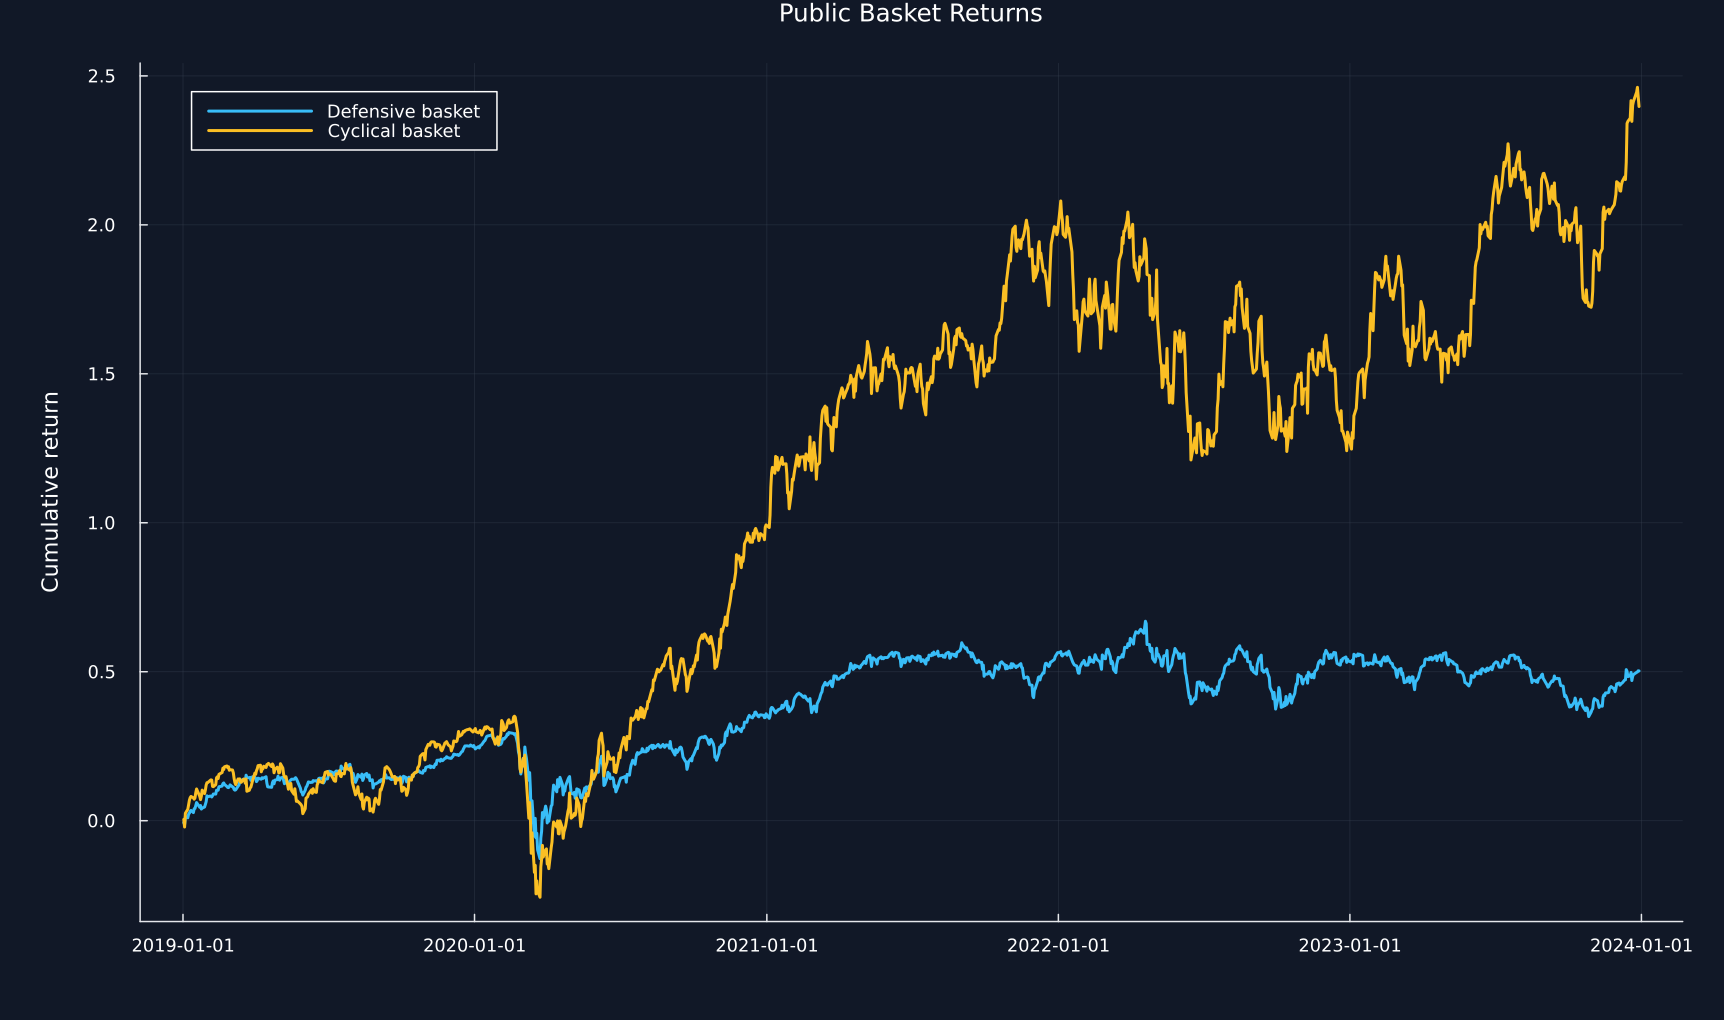

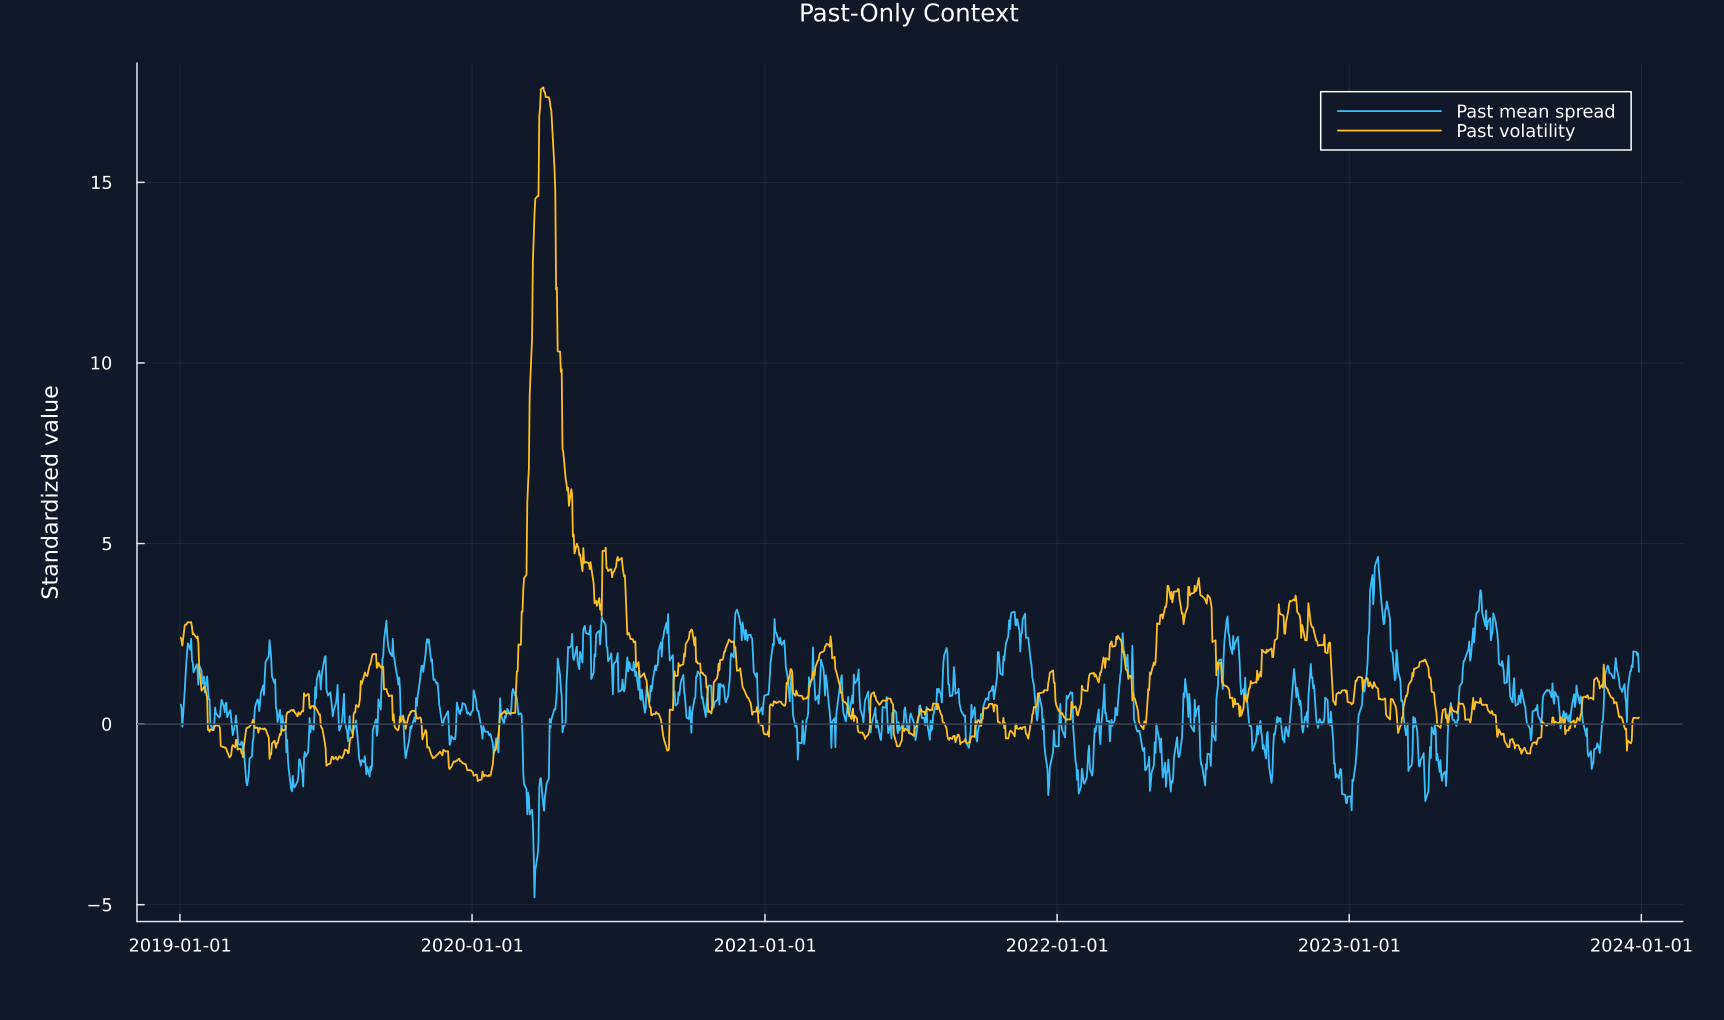

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("09_policy_evaluation");
using CSV,TOML,Printf
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore,normal_block
include(joinpath("..","support","BookPolicyStudy.jl"))
using .BookPolicyStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter09_random_inputs"),"policy")
captions=Dict("ipw_data_provenance"=>"Provenance of the public returns used in the policy illustration.","ipw_basket_definitions"=>"Fixed public basket definitions.","ipw_sample_contract"=>"Data and decision contract for the illustration.","ipw_context_summary"=>"Summary of the past-only context variables.","ipw_behavior_summary"=>"Summary of the generated behavior policy and realized actions.","ipw_candidate_definitions"=>"Five fixed target policies.","ipw_policy_values"=>"Public full-information values and inverse probability estimates.","ipw_weight_summary"=>"Importance-weight diagnostics for the five target policies.","ipw_manual_score_rows"=>"First eight contributions for the smooth momentum policy.","ipw_support_checks"=>"Overlap and probability checks for the main target policy.","ipw_overlap_sensitivity"=>"Sensitivity of the smooth momentum estimate to the behavior probability floor.","ipw_invalid_support_checks"=>"Required rejections for invalid probability support.","ipw_section_summary"=>"Summary of the inverse probability illustration.","dr_exact_cases"=>"Exact four-row double robustness check.","dr_exact_scores"=>"Row contributions in the exact double robustness check.","dr_fold_plan"=>"Chronological reward-prediction folds.","dr_oof_checks"=>"Information-boundary checks for reward predictions.","dr_prediction_quality"=>"Quality of chronological reward predictions against both public basket returns.","dr_oof_sample_rows"=>"Selected chronological reward predictions from the policy-selection period.","dr_policy_comparison"=>"Held-out full-information, inverse probability, and doubly robust values.","dr_score_summary"=>"Held-out score distributions for the smooth momentum policy.","dr_nuisance_scenarios"=>"Algebraic nuisance-input diagnostics for the smooth momentum policy.","dr_invalid_input_checks"=>"Required rejections for incompatible policy-evaluation inputs.","dr_section_summary"=>"Summary of the doubly robust evaluation.","selection_split"=>"Chronological split used for policy selection and evaluation.","selection_training_values"=>"Earlier-period doubly robust values used for selection.","selection_heldout_values"=>"Held-out values shown after the earlier policy choice.","selection_result"=>"Result of chronological selection followed by held-out evaluation.","selection_policy_action_shares"=>"Average action-one probabilities of the fixed candidates.","selection_outcome_isolation"=>"Selection is unchanged when only held-out outcomes are replaced.","selection_tie_rule"=>"First-candidate rule for exactly equal training values.","selection_invalid_checks"=>"Required rejections for invalid chronological splits.","selection_final_diagnostics"=>"Diagnostics for the policy chosen on earlier dates.","selection_section_summary"=>"Summary of chronological policy selection.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim9-"*replace(name,"_"=>"-"))
    return nothing
end
panel=build_policy_frame(store)
policy_names,candidates=candidate_policies(panel)
behavior=behavior_matrix(panel)
potential=potential_matrix(panel)
actions=panel.Action
rewards=panel[:,"Observed reward"]
predictions,fold_plan,fold_coefficients=chronological_predictions(panel)
data_file=joinpath(book_root(),"data","public","ken_french","49_Industry_Portfolios_daily_CSV.zip")
provenance=frame(["Item","Value"],[("Public source","Kenneth R. French 49 Industry Portfolios"),("Stored archive",basename(data_file)),("Archive bytes",filesize(data_file)),("Analysis start",string(first(panel.Date))),("Analysis end",string(last(panel.Date))),("Complete dates",nrow(panel)),("Download during execution","None")])
@assert nrow(panel)==1258
table(provenance,"ipw_data_provenance")
basket_definitions = frame(["Action","Basket","Industries","Daily return rule"],[[0,"Defensive","Food, Smoke, Health, Utilities","Equal weighted"],[1,"Cyclical","Building Materials, Steel, Machinery, Automobiles","Equal weighted"]])
table(basket_definitions,"ipw_basket_definitions")
sample_contract = frame(["Component","Source or rule"],[["Potential rewards","Both public basket returns on the same date"],["Context","Past returns only"],["Behavior action","Generated from a declared probability and random state 9,101"],["Behavior probability floor",0.1],["Target policies","Five fixed rules declared before held-out evaluation"]])
table(sample_contract,"ipw_sample_contract")
context_summary=frame(["Context","Dates","Mean","Standard deviation","Minimum","Maximum"],[(column,nrow(panel),mean(panel[:,column]),std(panel[:,column];corrected=true),minimum(panel[:,column]),maximum(panel[:,column])) for column in ["Past mean spread","Past volatility","Past one-day spread"]])
table(context_summary,"ipw_context_summary")
behavior_summary=frame(["Quantity","Value"],[("Minimum action probability",minimum(behavior)),("Maximum action probability",maximum(behavior)),("Mean probability of action 1",mean(behavior[:,2])),("Realized share of action 1",mean(actions)),("Action 0 dates",sum(actions.==0)),("Action 1 dates",sum(actions.==1))])
table(behavior_summary,"ipw_behavior_summary")
candidate_definitions=DataFrame("Policy"=>policy_names,"Probability of action 1"=>["0","1","One when the past mean spread is positive","Logistic function of 1.5 times the past mean spread","Logistic function of past spread and volatility"])
table(candidate_definitions,"ipw_candidate_definitions")
save_data(panel,paths,"policy_full_public_frame")
save_data(hcat(DataFrame("Date"=>panel.Date),DataFrame(predictions,["Predicted defensive reward","Predicted cyclical reward"])),paths,"policy_all_chronological_predictions")
save_data(fold_coefficients,paths,"policy_all_fold_coefficients")
cumulative=cumprod(1 .+potential;dims=1).-1
cumulative_data=hcat(DataFrame("Date"=>panel.Date),DataFrame(cumulative,["Defensive return","Cyclical return"]))
save_data(cumulative_data,paths,"ipw_basket_cumulative")
figure=plot(panel.Date,cumulative;color=[palette.cyan palette.amber],label=["Defensive basket" "Cyclical basket"],ylabel="Cumulative return",title="Public Basket Returns",size=(1150,680))
save_figure(figure,paths,"ipw_basket_cumulative")
context_data=panel[:,["Date","Past mean spread z","Past volatility z"]]
save_data(context_data,paths,"ipw_context_paths")
figure=plot(panel.Date,Matrix(context_data[:,2:3]);color=[palette.cyan palette.amber],label=["Past mean spread" "Past volatility"],linewidth=1.2,ylabel="Standardized value",title="Past-Only Context",size=(1150,680))
hline!(figure,[0.];color=palette.grid,linewidth=1,label="")
save_figure(figure,paths,"ipw_context_paths")


## Inverse Probability Value

For a target policy $pi(a\mid X_i)$ and behavior policy $\mu(a\mid X_i)$, the inverse probability estimate is

$$
\widehat V_{\mathrm{IPW}}(\pi)
=\frac{1}{n}\sum_{i=1}^{n}
\frac{\pi(A_i\mid X_i)}{\mu(A_i\mid X_i)}Y_i.
$$

Here, $n$ is the number of dates, $A_i$ is the logged action, $Y_i$ is its observed reward, and $X_i$ is the past-only context. The ratio gives more weight to a logged action when the target policy chooses it more often than the behavior policy did.

Row,Policy,Full-information value,IPW value,Absolute error
,String,Float64,Float64,Float64
1,Always defensive,0.000394058,0.000268618,0.00012544
2,Always cyclical,0.00116333,-0.000290441,0.00145378
3,Positive spread threshold,0.00072659,0.000318462,0.000408128
4,Smooth momentum,0.000844604,0.000443698,0.000400906
5,Volatility aware rule,0.000684446,0.000719484,3.50379e-5


Row,Policy,Effective sample size,Maximum weight,Mean weight
,String,Float64,Float64,Float64
1,Always defensive,522.477,6.55375,1.00722
2,Always cyclical,519.42,9.9835,1.01705
3,Positive spread threshold,699.62,6.92064,0.982218
4,Smooth momentum,1019.22,6.11885,0.98246
5,Volatility aware rule,1167.54,1.52412,0.993597


Row,Date,Action,Reward,Behavior probability,Target probability,Importance weight,Weighted reward
,String,Int64,Float64,Float64,Float64,Float64,Float64
1,2019-01-02,1,0.004275,0.388654,0.69201,1.78053,0.00761177
2,2019-01-03,1,-0.02535,0.417775,0.663136,1.58731,-0.0402382
3,2019-01-04,0,0.0269,0.720187,0.527095,0.731885,0.0196877
4,2019-01-07,1,0.012825,0.485841,0.800249,1.64714,0.0211246
5,2019-01-08,0,0.012075,0.47175,0.118607,0.251418,0.00303588
6,2019-01-09,0,0.00345,0.472552,0.0723369,0.153077,0.000528116
7,2019-01-10,1,0.00805,0.596548,0.952078,1.59598,0.0128476
8,2019-01-11,0,0.0026,0.405666,0.0337201,0.0831229,0.00021612


Row,Requirement,Status
,String,String
1,Every target-supported action has positive behavior probability,Pass
2,Every logged action has positive behavior probability,Pass
3,All behavior rows sum to one,Pass
4,All target rows sum to one,Pass


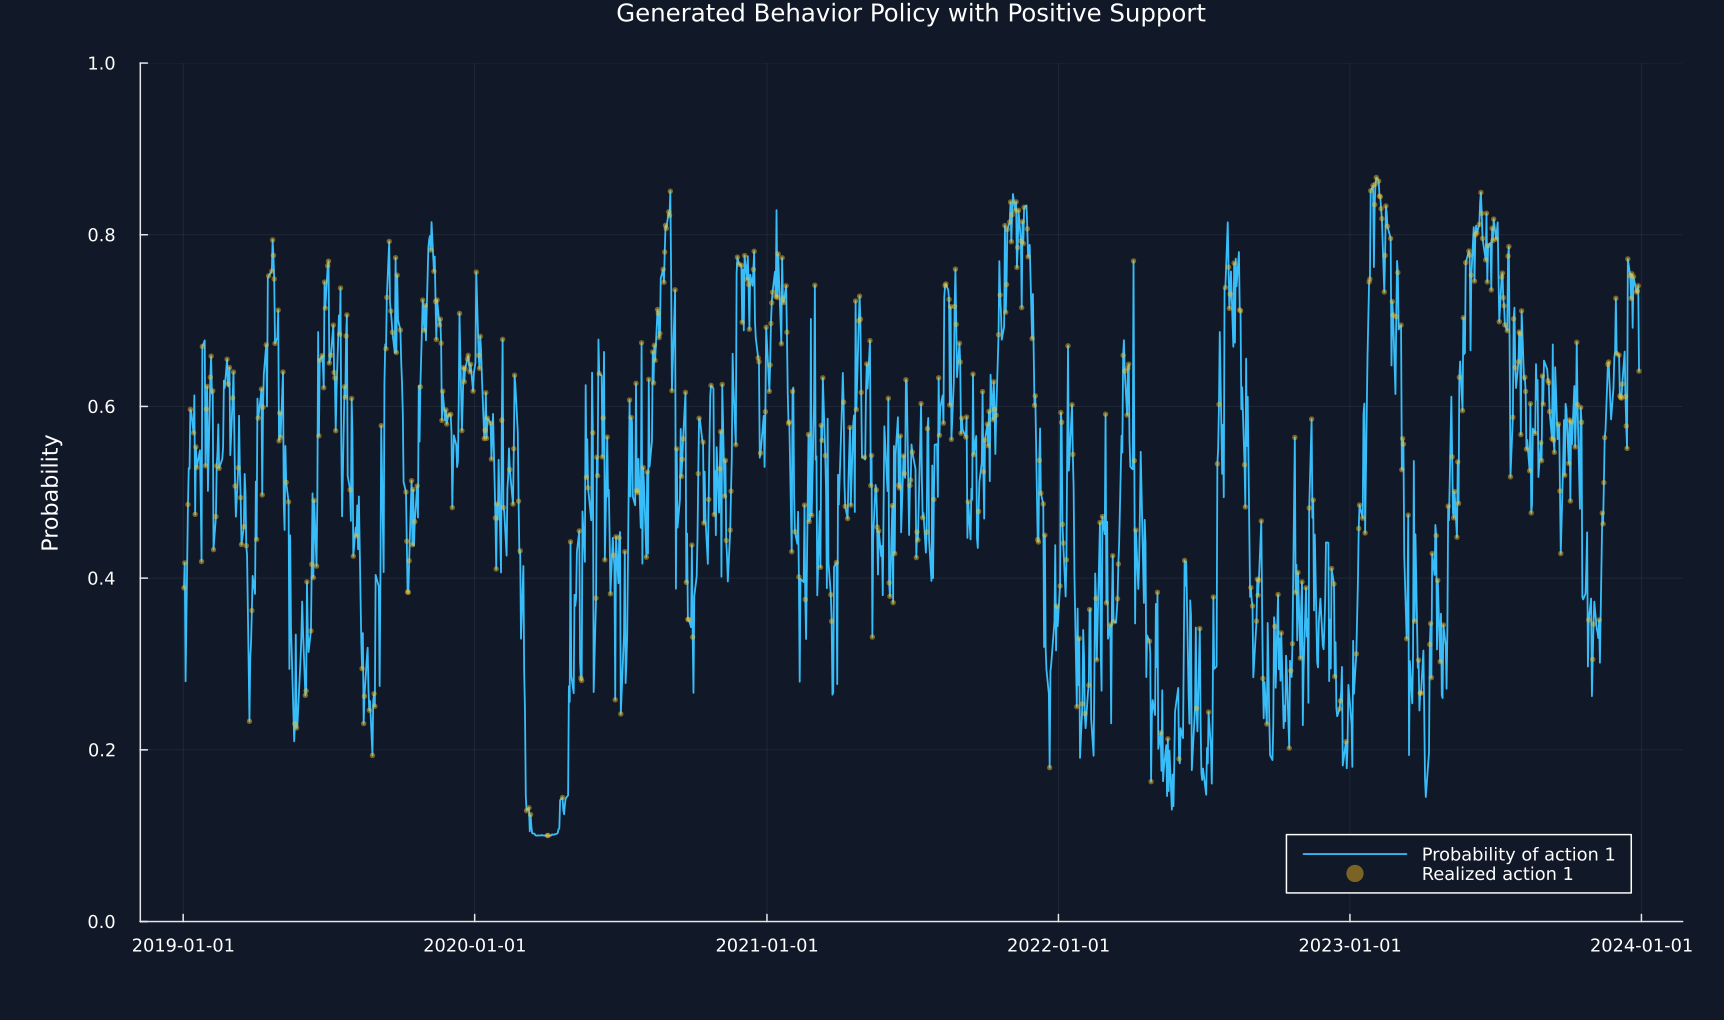

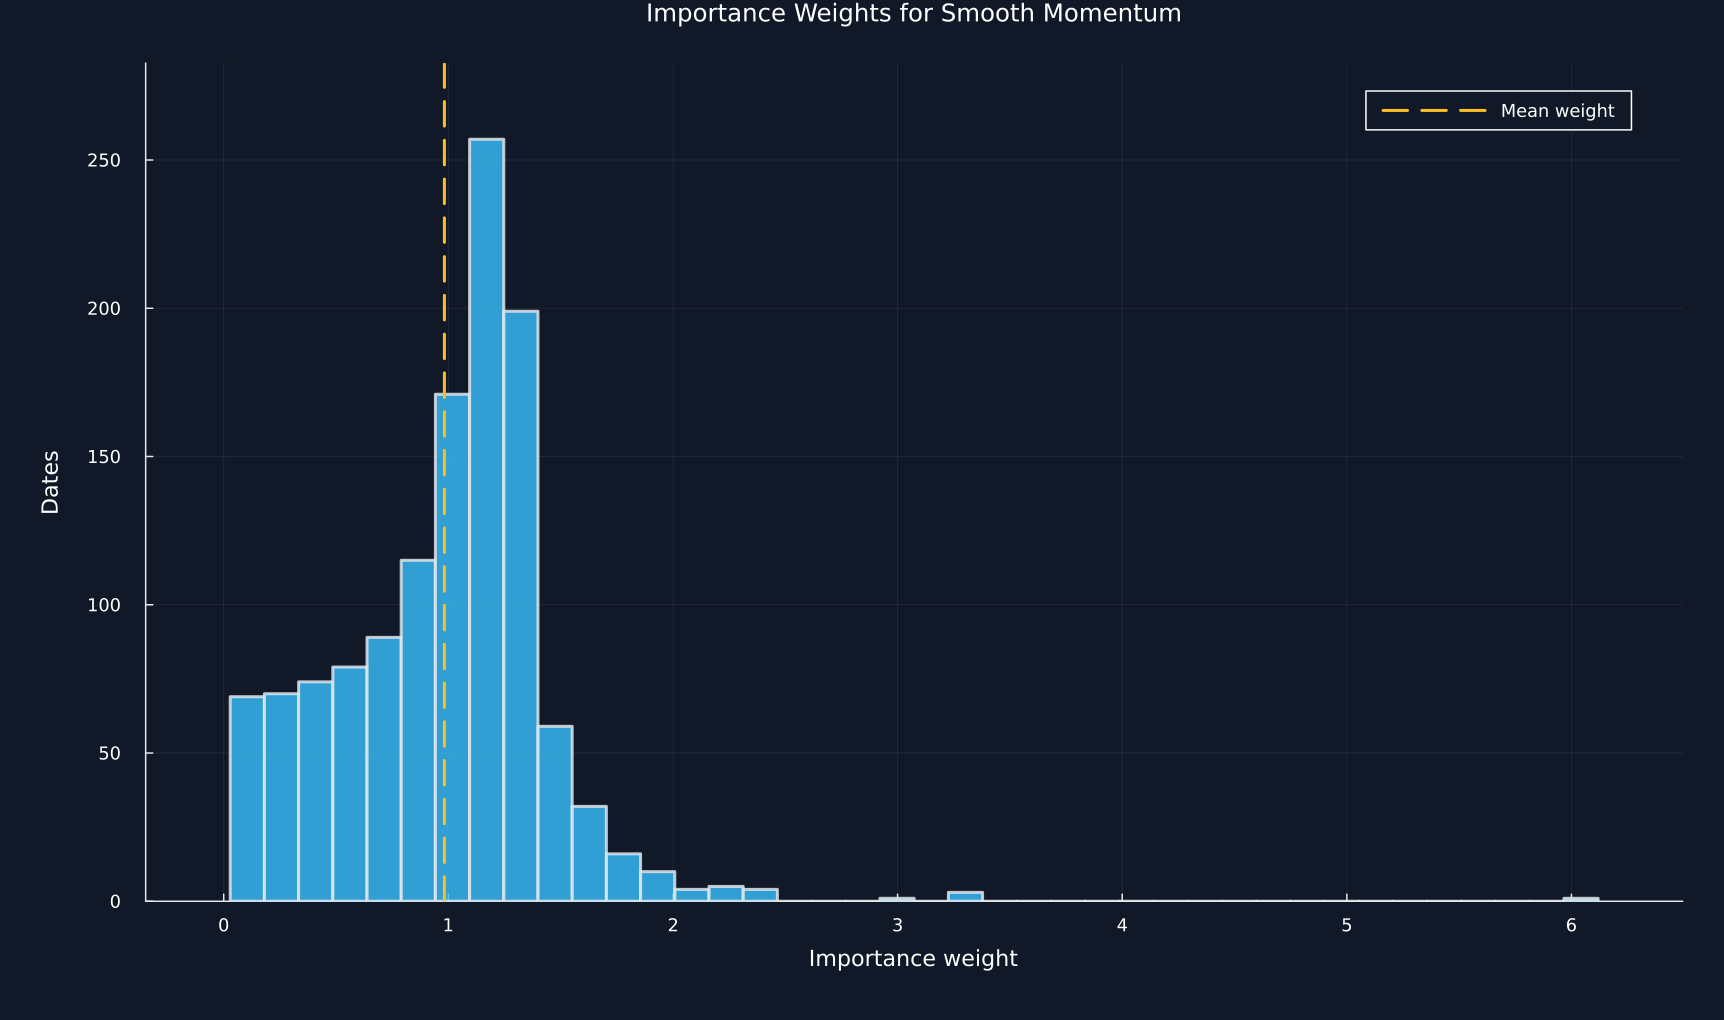

In [2]:
policy_rows=[]
weight_rows=[]
score_rows=[]
for (index,name) in enumerate(policy_names)
    policy=candidates[index,:,:]
    result=policy_evaluation(actions,rewards,behavior,policy,zeros(size(behavior)))
    truth=full_information_value(panel,policy)
    push!(policy_rows,(name,truth,result.ipw_value,abs(result.ipw_value-truth)))
    push!(weight_rows,(name,result.effective_sample_size,result.max_weight,result.mean_weight))
    for row in 1:nrow(panel)
        push!(score_rows,(index-1,panel.Date[row],actions[row],result.importance_weights[row],result.ipw_scores[row],result.dr_scores[row]))
    end
end
policy_values=frame(["Policy","Full-information value","IPW value","Absolute error"],policy_rows)
weight_summary=frame(["Policy","Effective sample size","Maximum weight","Mean weight"],weight_rows)
table(policy_values,"ipw_policy_values")
table(weight_summary,"ipw_weight_summary")
save_data(frame(["Policy number","Date","Action","Importance weight","IPW score","DR score"],score_rows),paths,"policy_all_full_sample_scores")
target=candidates[4,:,:]
target_result=policy_evaluation(actions,rewards,behavior,target,zeros(size(behavior)))
manual_rows=DataFrame("Date"=>string.(panel.Date[1:8]),"Action"=>actions[1:8],"Reward"=>rewards[1:8],"Behavior probability"=>[behavior[row,actions[row]+1] for row in 1:8],"Target probability"=>[target[row,actions[row]+1] for row in 1:8],"Importance weight"=>target_result.importance_weights[1:8],"Weighted reward"=>target_result.ipw_scores[1:8])
table(manual_rows,"ipw_manual_score_rows")
support_checks=frame(["Requirement","Status"],[("Every target-supported action has positive behavior probability",all(behavior[target.>0].>0)),("Every logged action has positive behavior probability",all(behavior[row,actions[row]+1]>0 for row in 1:nrow(panel))),("All behavior rows sum to one",all(isapprox.(vec(sum(behavior;dims=2)),1.))),("All target rows sum to one",all(isapprox.(vec(sum(target;dims=2)),1.)))])
table(support_checks,"ipw_support_checks")
behavior_plot=panel[:,["Date","Behavior probability action 1","Action"]]
save_data(behavior_plot,paths,"ipw_behavior_probabilities")
figure=plot(panel.Date,behavior[:,2];color=palette.cyan,linewidth=1.2,label="Probability of action 1",ylims=(0,1),ylabel="Probability",title="Generated Behavior Policy with Positive Support",size=(1150,680))
scatter!(figure,panel.Date[actions.==1],behavior[actions.==1,2];color=palette.amber,markersize=2,markerstrokewidth=0,alpha=.45,label="Realized action 1")
save_figure(figure,paths,"ipw_behavior_probabilities")
weight_plot=DataFrame("Importance weight"=>target_result.importance_weights)
save_data(weight_plot,paths,"ipw_weight_distribution")
weight_bins=histogram_counts(target_result.importance_weights,40)
save_data(weight_bins,paths,"ipw_weight_histogram_bins")
figure=bar((weight_bins[:,1]+weight_bins[:,2])/2,weight_bins.Count;bar_width=weight_bins[:,2]-weight_bins[:,1],color=palette.cyan,alpha=.82,label="",xlabel="Importance weight",ylabel="Dates",title="Importance Weights for Smooth Momentum",size=(1150,680),ylims=(0,1.1maximum(weight_bins.Count)))
vline!(figure,[target_result.mean_weight];color=palette.amber,linewidth=2,linestyle=:dash,label="Mean weight")
save_figure(figure,paths,"ipw_weight_distribution")


## Diagnosing weight variation under limited overlap

Overlap requires

$$
\mu(a\mid x)>0
\quad\text{whenever}\quad
\pi(a\mid x)>0.
$$

The condition says that a target action must have some chance of appearing under the behavior policy at every relevant context $x$. It permits inverse probability evaluation, but it does not promise small weights.

A useful summary of weight concentration is

$$
n_{\mathrm{eff}}
=\frac{\left(\sum_{i=1}^{n}w_i\right)^2}{\sum_{i=1}^{n}w_i^2},
\qquad
w_i=\frac{\pi(A_i\mid X_i)}{\mu(A_i\mid X_i)}.
$$

Here, $w_i$ is date $i$'s importance weight and $n_{\mathrm{eff}}$ is its effective sample size. A small value indicates that a few dates carry much of the weighted calculation.

Row,Probability floor,Minimum action probability,Realized action 1 share,Effective sample size,Maximum weight,IPW value,Full-information value,Absolute error
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.01,0.0100522,0.509539,937.656,13.7062,0.000362087,0.000844604,0.000482517
2,0.03,0.0300501,0.509539,978.659,10.7453,0.00045779,0.000844604,0.000386814
3,0.05,0.0500479,0.505564,997.375,8.83639,0.000458313,0.000844604,0.00038629
4,0.1,0.100043,0.509539,1019.22,6.11885,0.000443698,0.000844604,0.000400906
5,0.2,0.200032,0.503975,1015.09,3.78858,0.00049774,0.000844604,0.000346863


Row,Check,Rejected,Explanation
,String,String,String
1,Target action without behavior support,Pass,Stopped as required
2,Probability rows not summing to one,Pass,Stopped as required


Row,Result,Value
,String,String
1,Public reward information,Both basket returns are observed for every date
2,Generated component,Only the behavior action log and its probabilities
3,Behavior support,Every action probability is bounded away from zero
4,IPW interpretation,Average weighted reward for a fixed one-step target policy
5,Excluded interpretation,No sequential reinforcement learning or live performance claim


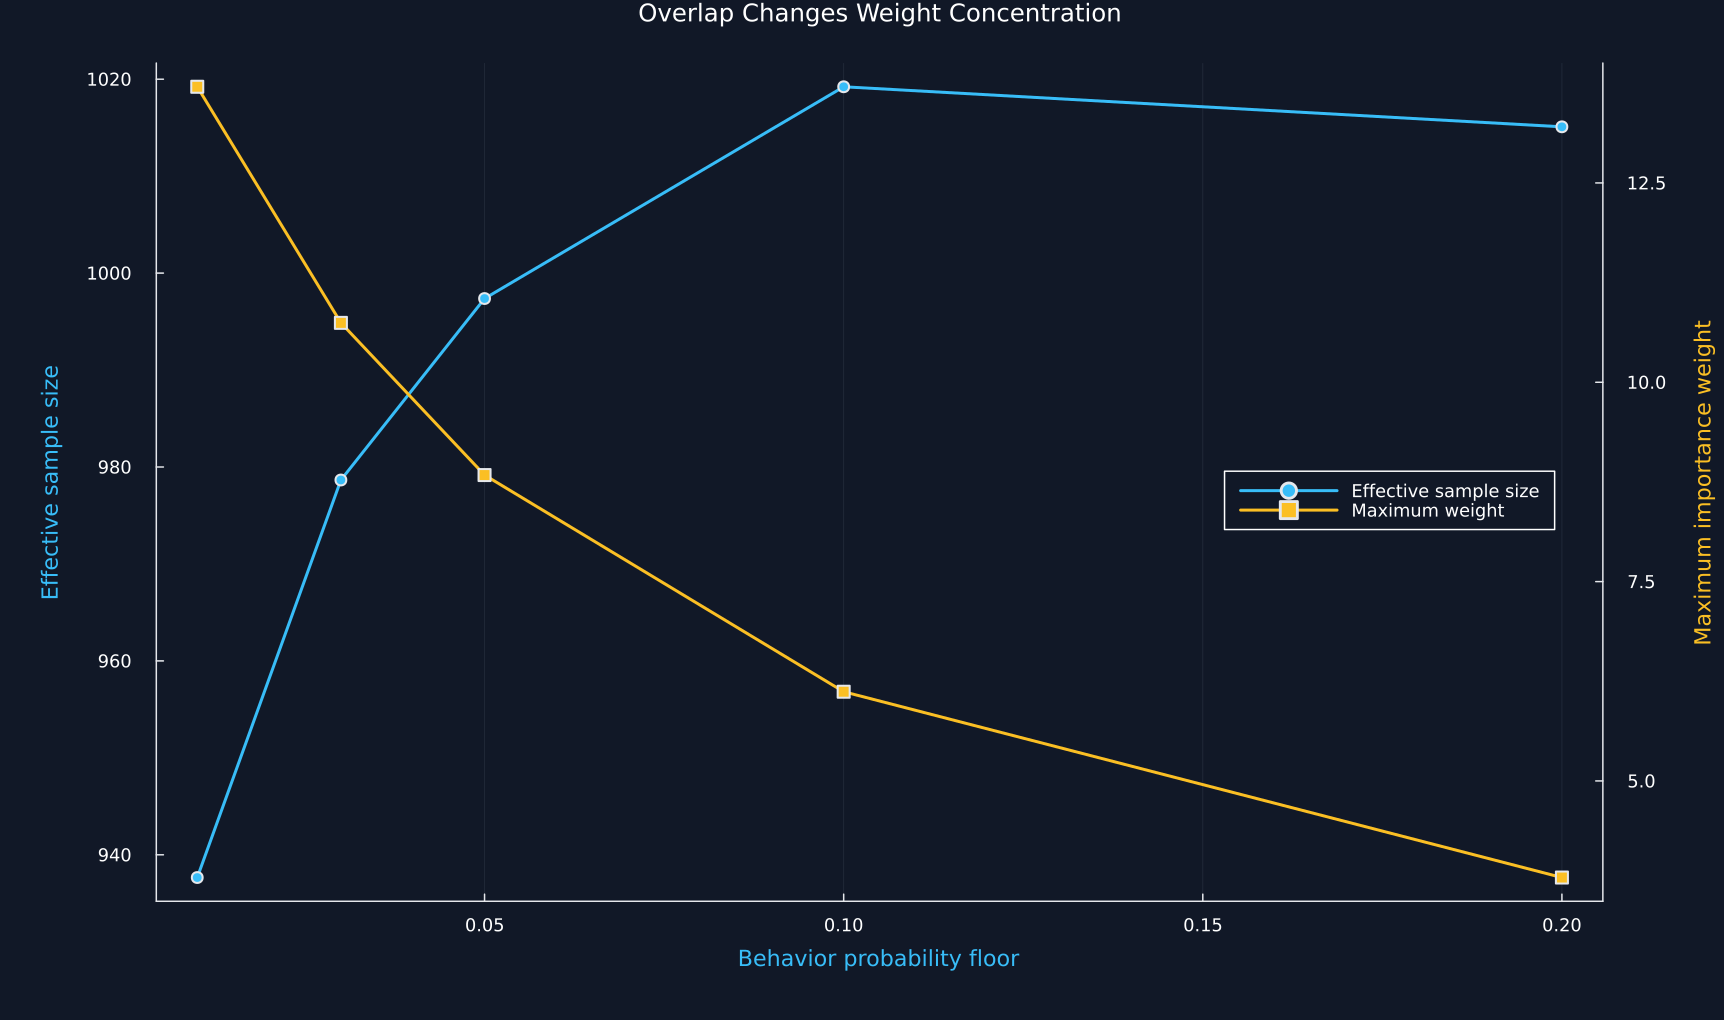

In [3]:
overlap_rows=[]
overlap_score_rows=[]
for floor in [.01,.03,.05,.10,.20]
    alternative=build_policy_frame(store;floor=floor)
    alternative_behavior=behavior_matrix(alternative)
    alternative_actions=alternative.Action
    alternative_rewards=alternative[:,"Observed reward"]
    alternative_target=candidate_policies(alternative)[2][4,:,:]
    result=policy_evaluation(alternative_actions,alternative_rewards,alternative_behavior,alternative_target,zeros(size(alternative_behavior)))
    truth=full_information_value(alternative,alternative_target)
    push!(overlap_rows,(floor,minimum(alternative_behavior),mean(alternative_actions),result.effective_sample_size,result.max_weight,result.ipw_value,truth,abs(result.ipw_value-truth)))
    for row in 1:nrow(alternative)
        push!(overlap_score_rows,(floor,alternative.Date[row],alternative_actions[row],alternative_behavior[row,2],alternative_rewards[row],result.importance_weights[row],result.ipw_scores[row]))
    end
end
overlap_sensitivity=frame(["Probability floor","Minimum action probability","Realized action 1 share","Effective sample size","Maximum weight","IPW value","Full-information value","Absolute error"],overlap_rows)
table(overlap_sensitivity,"ipw_overlap_sensitivity")
save_data(frame(["Probability floor","Date","Action","Behavior probability action 1","Observed reward","Importance weight","IPW score"],overlap_score_rows),paths,"policy_all_overlap_scores")
invalid_behavior=copy(behavior)
invalid_behavior[1,:]=[1.,0.]
invalid_policy=copy(target)
invalid_policy[1,:]=[0.,1.]
invalid_checks=frame(["Check","Rejected","Explanation"],[capture_failure("Target action without behavior support",()->policy_evaluation(actions,rewards,invalid_behavior,invalid_policy,predictions)),capture_failure("Probability rows not summing to one",()->policy_evaluation(actions,rewards,.9behavior,target,predictions))])
table(invalid_checks,"ipw_invalid_support_checks")
section_summary = frame(["Result","Value"],[["Public reward information","Both basket returns are observed for every date"],["Generated component","Only the behavior action log and its probabilities"],["Behavior support","Every action probability is bounded away from zero"],["IPW interpretation","Average weighted reward for a fixed one-step target policy"],["Excluded interpretation","No sequential reinforcement learning or live performance claim"]])
table(section_summary,"ipw_section_summary")
save_data(overlap_sensitivity,paths,"ipw_overlap_sensitivity")
figure=plot(overlap_sensitivity[:,1],overlap_sensitivity[:,4];color=palette.cyan,marker=:circle,label="Effective sample size",xlabel="Behavior probability floor",ylabel="Effective sample size",title="Overlap Changes Weight Concentration",size=(1150,680),legend=:right,foreground_color_guide=palette.cyan)
plot!(figure,[NaN],[NaN];color=palette.amber,marker=:square,label="Maximum weight")
right=twinx(figure)
plot!(right,overlap_sensitivity[:,1],overlap_sensitivity[:,5];color=palette.amber,marker=:square,label="",ylabel="Maximum importance weight",legend=false,foreground_color_guide=palette.amber)
save_figure(figure,paths,"ipw_overlap_sensitivity")
